# Insurance Policy PDF Processor

This notebook processes two insurance policy PDFs for RAG (Retrieval-Augmented Generation) preparation.

## Objectives:
1. Read and extract text from two policy PDFs
2. Pre-process and clean the content
3. Structure data for RAG implementation
4. Prepare embeddings-ready format

## Table of Contents:
1. [Setup and Dependencies](#setup)
2. [PDF Reading and Extraction](#extraction)
3. [Text Preprocessing](#preprocessing)
4. [Content Analysis](#analysis)
5. [Data Structuring for RAG](#structuring)
6. [Export and Save](#export)

## 1. Setup and Dependencies <a name="setup"></a>

In [1]:
# Import libraries
import os
import json
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from typing import List, Dict, Any, Tuple
import warnings
warnings.filterwarnings('ignore')

# PDF processing
import PyPDF2
import fitz  # PyMuPDF

# Text processing
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download NLTK data
try:
    nltk.data.find('tokenizers/punkt')
except LookupError:
    nltk.download('punkt')

try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords')

try:
    nltk.data.find('corpora/wordnet')
except LookupError:
    nltk.download('wordnet')

# Set up plotting
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

print("✅ All libraries imported successfully!")
print(f"📁 Current directory: {os.getcwd()}")
print(f"🐍 Python version: {os.sys.version}")

✅ All libraries imported successfully!
📁 Current directory: /Users/zhizhaoyan/Desktop/AI/competition/2025_Competition/insurance_phrase_2
🐍 Python version: 3.12.11 (main, Oct  9 2025, 04:37:24) [Clang 14.0.3 (clang-1403.0.22.14.1)]


[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/zhizhaoyan/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## 2. PDF Reading and Extraction <a name="extraction"></a>

In [2]:
class PDFProcessor:
    """
    A comprehensive PDF processor for insurance policy documents.
    """
    
    def __init__(self):
        self.processed_docs = []
        self.lemmatizer = WordNetLemmatizer()
        self.stop_words = set(stopwords.words('english'))
    
    def extract_text_from_pdf(self, pdf_path: str) -> Dict[str, Any]:
        """
        Extract text from PDF using multiple methods for better coverage.
        
        Args:
            pdf_path: Path to the PDF file
            
        Returns:
            Dictionary containing extracted text and metadata
        """
        print(f"📄 Processing PDF: {pdf_path}")
        
        if not os.path.exists(pdf_path):
            raise FileNotFoundError(f"PDF file not found: {pdf_path}")
        
        text = ""
        pages = []
        
        # Method 1: PyMuPDF (more reliable)
        try:
            doc = fitz.open(pdf_path)
            for page_num in range(len(doc)):
                page = doc.load_page(page_num)
                page_text = page.get_text()
                pages.append({
                    'page_number': page_num + 1,
                    'text': page_text,
                    'char_count': len(page_text)
                })
                text += page_text + "\n"
            doc.close()
            print(f"✅ Successfully extracted text using PyMuPDF ({len(pages)} pages)")
        except Exception as e:
            print(f"⚠️ PyMuPDF failed: {e}")
            
            # Method 2: PyPDF2 (fallback)
            try:
                with open(pdf_path, 'rb') as file:
                    pdf_reader = PyPDF2.PdfReader(file)
                    for page_num, page in enumerate(pdf_reader.pages):
                        page_text = page.extract_text()
                        pages.append({
                            'page_number': page_num + 1,
                            'text': page_text,
                            'char_count': len(page_text)
                        })
                        text += page_text + "\n"
                print(f"✅ Successfully extracted text using PyPDF2 ({len(pages)} pages)")
            except Exception as e2:
                print(f"❌ Both PDF extraction methods failed: {e2}")
                raise
        
        return {
            'file_path': pdf_path,
            'file_name': os.path.basename(pdf_path),
            'total_pages': len(pages),
            'total_characters': len(text),
            'pages': pages,
            'raw_text': text
        }
    
    def clean_text(self, text: str) -> str:
        """
        Clean and normalize extracted text.
        
        Args:
            text: Raw extracted text
            
        Returns:
            Cleaned text
        """
        # Remove excessive whitespace
        text = re.sub(r'\s+', ' ', text)
        
        # Remove special characters but keep important punctuation
        text = re.sub(r'[^\w\s\.\,\;\:\!\?\-\(\)\$\%\@]', '', text)
        
        # Normalize spacing around punctuation
        text = re.sub(r'\s+([.,;:!?])', r'\1', text)
        
        # Remove page numbers and headers/footers
        #text = re.sub(r'\b\d+\s*of\s*\d+\b', '', text)  # Remove "X of Y" pattern
        text = re.sub(r'Page\s+\d+', '', text)  # Remove "Page X"
        # DON'T remove standalone numbers - they contain important information!
        # text = re.sub(r'\b\d+\b', '', text)  # REMOVED - This was deleting important numbers like prices
        
        # Remove extra spaces
        text = re.sub(r'\s+', ' ', text)
        
        return text.strip()
    
    def extract_sections(self, text: str) -> List[Dict[str, Any]]:
        """
        Extract logical sections from the policy text.
        
        Args:
            text: Cleaned text
            
        Returns:
            List of sections with metadata
        """
        sections = []
        
        # Common insurance policy section patterns
        section_patterns = [
            r'(?i)(summary\s+of\s+benefits)',
            r'(?i)(coverage\s+details?)',
            r'(?i)(what\s+is\s+covered)',
            r'(?i)(what\s+you\s+pay)',
            r'(?i)(deductibles?)',
            r'(?i)(copayments?)',
            r'(?i)(coinsurance)',
            r'(?i)(out\s+of\s+pocket)',
            r'(?i)(exclusions?)',
            r'(?i)(limitations?)',
            r'(?i)(preauthorization)',
            r'(?i)(claims?)',
            r'(?i)(appeals?)',
            r'(?i)(grievances?)'
        ]
        
        # Split text into sentences
        sentences = sent_tokenize(text)
        
        current_section = {
            'title': 'Introduction',
            'content': '',
            'sentences': [],
            'word_count': 0,
            'key_terms': []
        }
        
        for sentence in sentences:
            # Check if sentence starts a new section
            section_found = False
            for pattern in section_patterns:
                if re.search(pattern, sentence):
                    # Save current section if it has content
                    if current_section['content'].strip():
                        current_section['word_count'] = len(current_section['content'].split())
                        sections.append(current_section.copy())
                    
                    # Start new section
                    current_section = {
                        'title': sentence[:50] + '...' if len(sentence) > 50 else sentence,
                        'content': sentence,
                        'sentences': [sentence],
                        'word_count': 0,
                        'key_terms': []
                    }
                    section_found = True
                    break
            
            if not section_found:
                current_section['content'] += ' ' + sentence
                current_section['sentences'].append(sentence)
        
        # Add the last section
        if current_section['content'].strip():
            current_section['word_count'] = len(current_section['content'].split())
            sections.append(current_section)
        
        return sections
    
    def extract_key_terms(self, text: str) -> List[str]:
        """
        Extract key insurance terms from text.
        
        Args:
            text: Input text
            
        Returns:
            List of key terms
        """
        # Insurance-specific terms
        insurance_terms = [
            'deductible', 'copay', 'coinsurance', 'premium', 'benefit',
            'coverage', 'exclusion', 'limitation', 'preauthorization',
            'claim', 'appeal', 'grievance', 'out-of-pocket', 'network',
            'provider', 'facility', 'emergency', 'urgent', 'primary care',
            'specialist', 'prescription', 'generic', 'brand', 'formulary'
        ]
        
        # Find terms in text
        found_terms = []
        text_lower = text.lower()
        
        for term in insurance_terms:
            if term in text_lower:
                found_terms.append(term)
        
        # Extract dollar amounts
        dollar_amounts = re.findall(r'\$\d+(?:\.\d{2})?', text)
        found_terms.extend(dollar_amounts)
        
        # Extract percentages
        percentages = re.findall(r'\d+%', text)
        found_terms.extend(percentages)
        
        return list(set(found_terms))
    
    def process_pdf(self, pdf_path: str) -> Dict[str, Any]:
        """
        Complete processing pipeline for a PDF.
        
        Args:
            pdf_path: Path to PDF file
            
        Returns:
            Processed document data
        """
        # Extract text
        doc_data = self.extract_text_from_pdf(pdf_path)
        
        # Clean text
        cleaned_text = self.clean_text(doc_data['raw_text'])
        doc_data['cleaned_text'] = cleaned_text
        
        # Extract sections
        sections = self.extract_sections(cleaned_text)
        doc_data['sections'] = sections
        
        # Extract key terms
        key_terms = self.extract_key_terms(cleaned_text)
        doc_data['key_terms'] = key_terms
        
        # Calculate statistics
        doc_data['statistics'] = {
            'total_words': len(cleaned_text.split()),
            'total_sentences': len(sent_tokenize(cleaned_text)),
            'total_sections': len(sections),
            'avg_words_per_section': np.mean([s['word_count'] for s in sections]) if sections else 0,
            'key_terms_count': len(key_terms)
        }
        
        return doc_data

# Initialize processor
processor = PDFProcessor()
print("✅ PDFProcessor initialized successfully!")

✅ PDFProcessor initialized successfully!


In [3]:
# Define PDF file paths - Update these to your actual files
pdf_files = [
    "policy1.pdf",  # Your first policy PDF
    "policy2.pdf"   # Your second policy PDF
]

# Check if files exist
print("📁 Checking PDF files:")
for pdf_file in pdf_files:
    if os.path.exists(pdf_file):
        print(f"✅ Found: {pdf_file}")
    else:
        print(f"❌ Not found: {pdf_file}")
        print(f"   Current directory: {os.getcwd()}")
        print(f"   Please update the path or place the PDF in this directory")

# Process PDFs
processed_docs = []
for pdf_file in pdf_files:
    if os.path.exists(pdf_file):
        print(f"\n🔄 Processing {pdf_file}...")
        doc_data = processor.process_pdf(pdf_file)
        processed_docs.append(doc_data)
        print(f"✅ Completed processing {pdf_file}")
        print(f"   Pages: {doc_data['total_pages']}, Words: {doc_data['statistics']['total_words']:,}")
    else:
        print(f"❌ Skipping {pdf_file} - file not found")

📁 Checking PDF files:
✅ Found: policy1.pdf
✅ Found: policy2.pdf

🔄 Processing policy1.pdf...
📄 Processing PDF: policy1.pdf
✅ Successfully extracted text using PyMuPDF (12 pages)
✅ Completed processing policy1.pdf
   Pages: 12, Words: 3,112

🔄 Processing policy2.pdf...
📄 Processing PDF: policy2.pdf
✅ Successfully extracted text using PyMuPDF (9 pages)
✅ Completed processing policy2.pdf
   Pages: 9, Words: 2,539


In [4]:
 processed_docs[0]['sections'][0]

{'title': 'A48551 (125) 1 Summary of Benefits Group Plan HMO ...',
 'content': 'A48551 (125) 1 Summary of Benefits Group Plan HMO Plan Platinum Trio HMO 030 OffEx This Summary of Benefits shows the amount you will pay for Covered Services under this Blue Shield of California Plan. It is only a summary and it is included as part of the Evidence of Coverage (EOC).1 Please read both documents carefully for details. Medical Provider Network: Trio ACO HMO Network This Plan uses a specific network of Health Care Providers, called the Trio ACO HMO provider network. Medical Groups, Independent Practice Associations (IPAs), and Physicians in this network are called Participating Providers. You must select a Primary Care Physician from this network to provide your primary care and help you access services, but there are some exceptions. Please review your Evidence of Coverage for details about how to access care under this Plan. You can find Participating Providers in this network at blueshieldc

## 3. Text Preprocessing <a name="preprocessing"></a>

In [5]:
# Advanced text preprocessing functions

def advanced_text_cleaning(text: str) -> str:
    """
    Advanced text cleaning for insurance documents.
    """
    # Remove headers and footers
    text = re.sub(r'^.*?(?=Summary|Coverage|Benefits)', text, '', flags=re.MULTILINE | re.DOTALL)
    
    # Normalize common insurance terms
    replacements = {
        'co-pay': 'copay',
        'co pay': 'copay',
        'out of pocket': 'out-of-pocket',
        'pre auth': 'preauthorization',
        'pre-auth': 'preauthorization'
    }
    
    for old, new in replacements.items():
        text = re.sub(old, new, text, flags=re.IGNORECASE)
    
    # Remove excessive punctuation
    text = re.sub(r'[.]{3,}', '...', text)
    text = re.sub(r'[-]{3,}', '---', text)
    
    # Clean up whitespace
    text = re.sub(r'\s+', ' ', text)
    
    return text.strip()

def extract_financial_info(text: str) -> Dict[str, List[str]]:
    """
    Extract financial information from text.
    """
    # Dollar amounts
    dollar_amounts = re.findall(r'\$\d+(?:\.\d{2})?', text)
    
    # Percentages
    percentages = re.findall(r'\d+(?:\.\d+)?%', text)
    
    # Deductible amounts
    deductible_patterns = [
        r'deductible[\s:]*\$?(\d+(?:\.\d{2})?)',
        r'\$?(\d+(?:\.\d{2})?)[\s]*deductible'
    ]
    
    deductibles = []
    for pattern in deductible_patterns:
        matches = re.findall(pattern, text, re.IGNORECASE)
        deductibles.extend([f"${match}" if not match.startswith('$') else match for match in matches])
    
    # Co-pay amounts
    copay_patterns = [
        r'copay[\s:]*\$?(\d+(?:\.\d{2})?)',
        r'\$?(\d+(?:\.\d{2})?)[\s]*copay'
    ]
    
    copays = []
    for pattern in copay_patterns:
        matches = re.findall(pattern, text, re.IGNORECASE)
        copays.extend([f"${match}" if not match.startswith('$') else match for match in matches])
    
    return {
        'dollar_amounts': list(set(dollar_amounts)),
        'percentages': list(set(percentages)),
        'deductibles': list(set(deductibles)),
        'copays': list(set(copays))
    }

def create_chunks_for_rag(text: str, chunk_size: int = 500, overlap: int = 50) -> List[Dict[str, Any]]:
    """
    Create chunks optimized for RAG.
    
    Args:
        text: Input text
        chunk_size: Target chunk size in characters
        overlap: Overlap between chunks
        
    Returns:
        List of chunks with metadata
    """
    sentences = sent_tokenize(text)
    chunks = []
    
    current_chunk = ""
    chunk_id = 0
    
    for i, sentence in enumerate(sentences):
        # If adding this sentence would exceed chunk size
        if len(current_chunk) + len(sentence) > chunk_size and current_chunk:
            # Save current chunk
            chunks.append({
                'chunk_id': chunk_id,
                'text': current_chunk.strip(),
                'char_count': len(current_chunk),
                'word_count': len(current_chunk.split()),
                'sentence_count': len(sent_tokenize(current_chunk)),
                'start_sentence': i - len(current_chunk.split('.')) + 1,
                'end_sentence': i,
                'financial_info': extract_financial_info(current_chunk),
                'key_terms': extract_key_terms(current_chunk)
            })
            chunk_id += 1
            
            # Start new chunk with overlap
            if overlap > 0:
                # Find the last few sentences that fit in overlap
                overlap_text = ""
                for j in range(i-1, max(0, i-5), -1):
                    if len(overlap_text) + len(sentences[j]) <= overlap:
                        overlap_text = sentences[j] + " " + overlap_text
                    else:
                        break
                current_chunk = overlap_text
            else:
                current_chunk = ""
        
        current_chunk += sentence + " "
    
    # Add the last chunk
    if current_chunk.strip():
        chunks.append({
            'chunk_id': chunk_id,
            'text': current_chunk.strip(),
            'char_count': len(current_chunk),
            'word_count': len(current_chunk.split()),
            'sentence_count': len(sent_tokenize(current_chunk)),
            'start_sentence': max(0, len(sentences) - len(current_chunk.split('.'))),
            'end_sentence': len(sentences) - 1,
            'financial_info': extract_financial_info(current_chunk),
            'key_terms': extract_key_terms(current_chunk)
        })
    
    return chunks

def extract_key_terms(text: str) -> List[str]:
    """
    Extract key insurance terms from text.
    """
    # Insurance-specific terms
    insurance_terms = [
        'deductible', 'copay', 'coinsurance', 'premium', 'benefit',
        'coverage', 'exclusion', 'limitation', 'preauthorization',
        'claim', 'appeal', 'grievance', 'out-of-pocket', 'network',
        'provider', 'facility', 'emergency', 'urgent', 'primary care',
        'specialist', 'prescription', 'generic', 'brand', 'formulary'
    ]
    
    # Find terms in text
    found_terms = []
    text_lower = text.lower()
    
    for term in insurance_terms:
        if term in text_lower:
            found_terms.append(term)
    
    # Extract dollar amounts
    dollar_amounts = re.findall(r'\$\d+(?:\.\d{2})?', text)
    found_terms.extend(dollar_amounts)
    
    # Extract percentages
    percentages = re.findall(r'\d+%', text)
    found_terms.extend(percentages)
    
    return list(set(found_terms))

print("✅ Advanced preprocessing functions defined!")

✅ Advanced preprocessing functions defined!


## 4. Content Analysis <a name="analysis"></a>

In [6]:
# Analysis functions

def analyze_document_structure(doc_data: Dict[str, Any]) -> pd.DataFrame:
    """
    Analyze the structure of a processed document.
    """
    sections_df = pd.DataFrame(doc_data['sections'])
    
    if not sections_df.empty:
        sections_df['char_count'] = sections_df['content'].str.len()
        sections_df['sentence_count'] = sections_df['sentences'].str.len()
    
    return sections_df

def compare_documents(doc1_data: Dict[str, Any], doc2_data: Dict[str, Any]) -> Dict[str, Any]:
    """
    Compare two processed documents.
    """
    comparison = {
        'document_names': [doc1_data['file_name'], doc2_data['file_name']],
        'page_counts': [doc1_data['total_pages'], doc2_data['total_pages']],
        'character_counts': [doc1_data['total_characters'], doc2_data['total_characters']],
        'word_counts': [doc1_data['statistics']['total_words'], doc2_data['statistics']['total_words']],
        'section_counts': [doc1_data['statistics']['total_sections'], doc2_data['statistics']['total_sections']],
        'key_terms_counts': [doc1_data['statistics']['key_terms_count'], doc2_data['statistics']['key_terms_count']]
    }
    
    # Find common key terms
    terms1 = set(doc1_data['key_terms'])
    terms2 = set(doc2_data['key_terms'])
    comparison['common_terms'] = list(terms1.intersection(terms2))
    comparison['unique_to_doc1'] = list(terms1 - terms2)
    comparison['unique_to_doc2'] = list(terms2 - terms1)
    
    return comparison

def visualize_document_comparison(comparison: Dict[str, Any]):
    """
    Create visualizations comparing two documents.
    """
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # Page counts
    axes[0, 0].bar(comparison['document_names'], comparison['page_counts'], color=['skyblue', 'lightcoral'])
    axes[0, 0].set_title('Page Counts')
    axes[0, 0].set_ylabel('Number of Pages')
    
    # Word counts
    axes[0, 1].bar(comparison['document_names'], comparison['word_counts'], color=['lightgreen', 'gold'])
    axes[0, 1].set_title('Word Counts')
    axes[0, 1].set_ylabel('Number of Words')
    
    # Section counts
    axes[1, 0].bar(comparison['document_names'], comparison['section_counts'], color=['plum', 'orange'])
    axes[1, 0].set_title('Section Counts')
    axes[1, 0].set_ylabel('Number of Sections')
    
    # Key terms comparison
    term_categories = ['Common Terms', 'Unique to Doc 1', 'Unique to Doc 2']
    term_counts = [
        len(comparison['common_terms']),
        len(comparison['unique_to_doc1']),
        len(comparison['unique_to_doc2'])
    ]
    axes[1, 1].bar(term_categories, term_counts, color=['purple', 'red', 'blue'])
    axes[1, 1].set_title('Key Terms Distribution')
    axes[1, 1].set_ylabel('Number of Terms')
    axes[1, 1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

print("✅ Analysis functions defined!")

✅ Analysis functions defined!


## 5. Data Structuring for RAG <a name="structuring"></a>

In [7]:
# RAG-optimized data structure

def create_rag_dataset(processed_docs: List[Dict[str, Any]]) -> Dict[str, Any]:
    """
    Create a dataset optimized for RAG implementation.
    
    Args:
        processed_docs: List of processed document data
        
    Returns:
        RAG-optimized dataset
    """
    rag_dataset = {
        'metadata': {
            'total_documents': len(processed_docs),
            'creation_date': pd.Timestamp.now().isoformat(),
            'processing_version': '1.0'
        },
        'documents': [],
        'chunks': [],
        'embeddings_ready': False
    }
    
    chunk_id_counter = 0
    
    for doc_idx, doc_data in enumerate(processed_docs):
        # Document-level metadata
        doc_info = {
            'document_id': doc_idx,
            'file_name': doc_data['file_name'],
            'file_path': doc_data['file_path'],
            'total_pages': doc_data['total_pages'],
            'statistics': doc_data['statistics'],
            'key_terms': doc_data['key_terms']
        }
        rag_dataset['documents'].append(doc_info)
        
        # Create chunks for this document
        chunks = create_chunks_for_rag(doc_data['cleaned_text'])
        
        for chunk in chunks:
            chunk['document_id'] = doc_idx
            chunk['chunk_id'] = chunk_id_counter
            chunk['document_name'] = doc_data['file_name']
            
            # Add RAG-specific metadata
            chunk['rag_metadata'] = {
                'embedding_text': chunk['text'],  # Text ready for embedding
                'search_keywords': chunk['key_terms'],
                'financial_values': chunk['financial_info'],
                'content_type': 'insurance_policy',
                'processing_timestamp': pd.Timestamp.now().isoformat()
            }
            
            rag_dataset['chunks'].append(chunk)
            chunk_id_counter += 1
    
    # Add summary statistics
    rag_dataset['summary'] = {
        'total_chunks': len(rag_dataset['chunks']),
        'avg_chunk_size': np.mean([c['char_count'] for c in rag_dataset['chunks']]) if rag_dataset['chunks'] else 0,
        'total_words': sum([c['word_count'] for c in rag_dataset['chunks']]),
        'unique_key_terms': len(set([term for chunk in rag_dataset['chunks'] for term in chunk['key_terms']]))
    }
    
    return rag_dataset

def prepare_for_embeddings(rag_dataset: Dict[str, Any]) -> List[Dict[str, Any]]:
    """
    Prepare text chunks for embedding generation with policy identification.
    
    Args:
        rag_dataset: RAG dataset
        
    Returns:
        List of structured texts ready for embedding, each with policy identification
    """
    embedding_texts = []
    
    for chunk in rag_dataset['chunks']:
        # Create enhanced text for embedding
        enhanced_text = f"{chunk['text']}"
        
        # Add key terms as context
        if chunk['key_terms']:
            enhanced_text += f" Keywords: {', '.join(chunk['key_terms'])}"
        
        # Add financial info as context
        if chunk['financial_info']['dollar_amounts']:
            enhanced_text += f" Costs: {', '.join(chunk['financial_info']['dollar_amounts'])}"
        
        # Create structured embedding data with policy identification
        embedding_data = {
            'chunk_id': chunk['chunk_id'],
            'document_id': chunk['document_id'],
            'document_name': chunk['document_name'],
            'policy_identifier': f"Policy_{chunk['document_id']}_{chunk['document_name']}",
            'embedding_text': enhanced_text,
            'original_text': chunk['text'],
            'metadata': {
                'char_count': chunk['char_count'],
                'word_count': chunk['word_count'],
                'key_terms': chunk['key_terms'],
                'financial_info': chunk['financial_info'],
                'search_keywords': chunk['rag_metadata']['search_keywords']
            }
        }
        
        embedding_texts.append(embedding_data)
    
    return embedding_texts

def create_policy_comparison_dataset(rag_dataset: Dict[str, Any]) -> Dict[str, Any]:
    """
    Create a dataset optimized for policy comparison.
    
    Args:
        rag_dataset: RAG dataset
        
    Returns:
        Policy comparison dataset with separate collections for each policy
    """
    comparison_dataset = {
        'metadata': {
            'total_policies': rag_dataset['metadata']['total_documents'],
            'creation_date': pd.Timestamp.now().isoformat(),
            'purpose': 'policy_comparison'
        },
        'policies': {},
        'comparison_metadata': {}
    }
    
    # Group chunks by policy
    for doc in rag_dataset['documents']:
        policy_id = doc['document_id']
        policy_name = doc['file_name']
        
        # Get all chunks for this policy
        policy_chunks = [chunk for chunk in rag_dataset['chunks'] 
                        if chunk['document_id'] == policy_id]
        
        # Create policy-specific data
        comparison_dataset['policies'][f'policy_{policy_id}'] = {
            'policy_id': policy_id,
            'policy_name': policy_name,
            'file_path': doc['file_path'],
            'total_pages': doc['total_pages'],
            'statistics': doc['statistics'],
            'key_terms': doc['key_terms'],
            'chunks': policy_chunks,
            'embedding_ready_chunks': []
        }
        
        # Prepare embedding-ready chunks for this policy
        for chunk in policy_chunks:
            enhanced_text = f"{chunk['text']}"
            
            # Add key terms as context
            if chunk['key_terms']:
                enhanced_text += f" Keywords: {', '.join(chunk['key_terms'])}"
            
            # Add financial info as context
            if chunk['financial_info']['dollar_amounts']:
                enhanced_text += f" Costs: {', '.join(chunk['financial_info']['dollar_amounts'])}"
            
            embedding_chunk = {
                'chunk_id': chunk['chunk_id'],
                'policy_id': policy_id,
                'policy_name': policy_name,
                'embedding_text': enhanced_text,
                'original_text': chunk['text'],
                'metadata': {
                    'char_count': chunk['char_count'],
                    'word_count': chunk['word_count'],
                    'key_terms': chunk['key_terms'],
                    'financial_info': chunk['financial_info']
                }
            }
            
            comparison_dataset['policies'][f'policy_{policy_id}']['embedding_ready_chunks'].append(embedding_chunk)
    
    # Add comparison metadata
    comparison_dataset['comparison_metadata'] = {
        'total_policies': len(comparison_dataset['policies']),
        'policy_names': [comp_dataset['policy_name'] for comp_dataset in comparison_dataset['policies'].values()],
        'total_chunks_per_policy': {
            f'policy_{pid}': len(comp_dataset['chunks']) 
            for pid, comp_dataset in comparison_dataset['policies'].items()
        }
    }
    
    return comparison_dataset

def get_policy_specific_embeddings(comparison_dataset: Dict[str, Any], policy_id: int) -> List[str]:
    """
    Get embedding texts for a specific policy.
    
    Args:
        comparison_dataset: Policy comparison dataset
        policy_id: ID of the policy to get embeddings for
        
    Returns:
        List of embedding texts for the specified policy
    """
    policy_key = f'policy_{policy_id}'
    if policy_key not in comparison_dataset['policies']:
        raise ValueError(f"Policy {policy_id} not found in dataset")
    
    return [chunk['embedding_text'] for chunk in 
            comparison_dataset['policies'][policy_key]['embedding_ready_chunks']]

def search_across_policies(comparison_dataset: Dict[str, Any], query: str, top_k: int = 5) -> Dict[str, List[Dict[str, Any]]]:
    """
    Search for query across all policies and return results grouped by policy.
    
    Args:
        comparison_dataset: Policy comparison dataset
        query: Search query
        top_k: Number of top results per policy
        
    Returns:
        Dictionary with results grouped by policy
    """
    # This is a placeholder for actual search implementation
    # In a real implementation, you would use vector similarity search here
    results = {}
    
    for policy_key, policy_data in comparison_dataset['policies'].items():
        policy_results = []
        
        # Simple keyword matching (replace with actual vector search)
        query_lower = query.lower()
        for chunk in policy_data['embedding_ready_chunks']:
            if query_lower in chunk['embedding_text'].lower():
                policy_results.append({
                    'chunk_id': chunk['chunk_id'],
                    'policy_id': chunk['policy_id'],
                    'policy_name': chunk['policy_name'],
                    'text': chunk['original_text'],
                    'embedding_text': chunk['embedding_text'],
                    'metadata': chunk['metadata']
                })
        
        # Sort by relevance (simple implementation)
        policy_results.sort(key=lambda x: len(x['text']), reverse=True)
        results[policy_key] = policy_results[:top_k]
    
    return results

print("✅ RAG data structuring functions defined!")

✅ RAG data structuring functions defined!


## 6. Export and Save <a name="export"></a>

In [8]:
# Export functions

def save_processed_data(rag_dataset: Dict[str, Any], output_dir: str = "processed_data"):
    """
    Save processed data in multiple formats for different use cases.
    
    Args:
        rag_dataset: RAG dataset to save
        output_dir: Directory to save files
    """
    os.makedirs(output_dir, exist_ok=True)
    
    # Save complete dataset as JSON
    with open(os.path.join(output_dir, 'rag_dataset.json'), 'w', encoding='utf-8') as f:
        json.dump(rag_dataset, f, indent=2, ensure_ascii=False)
    
    # Save chunks as CSV for easy analysis
    chunks_df = pd.DataFrame(rag_dataset['chunks'])
    chunks_df.to_csv(os.path.join(output_dir, 'chunks.csv'), index=False)
    
    # Save embedding-ready texts with policy identification
    embedding_texts = prepare_for_embeddings(rag_dataset)
    with open(os.path.join(output_dir, 'embedding_texts.json'), 'w', encoding='utf-8') as f:
        json.dump(embedding_texts, f, indent=2, ensure_ascii=False)
    
    # Also save a simplified version for backward compatibility
    simple_embedding_texts = [item['embedding_text'] for item in embedding_texts]
    with open(os.path.join(output_dir, 'embedding_texts_simple.json'), 'w', encoding='utf-8') as f:
        json.dump(simple_embedding_texts, f, indent=2, ensure_ascii=False)
    
    # Save policy comparison dataset
    comparison_dataset = create_policy_comparison_dataset(rag_dataset)
    with open(os.path.join(output_dir, 'policy_comparison_dataset.json'), 'w', encoding='utf-8') as f:
        json.dump(comparison_dataset, f, indent=2, ensure_ascii=False)
    
    # Save metadata summary
    summary = {
        'processing_summary': rag_dataset['summary'],
        'document_info': rag_dataset['documents'],
        'export_timestamp': pd.Timestamp.now().isoformat()
    }
    
    with open(os.path.join(output_dir, 'processing_summary.json'), 'w', encoding='utf-8') as f:
        json.dump(summary, f, indent=2, ensure_ascii=False)
    
    print(f"✅ Data saved to {output_dir}/")
    print(f"   - rag_dataset.json: Complete dataset")
    print(f"   - chunks.csv: Chunks in tabular format")
    print(f"   - embedding_texts.json: Structured texts with policy identification")
    print(f"   - embedding_texts_simple.json: Simple text list (backward compatibility)")
    print(f"   - policy_comparison_dataset.json: Optimized for policy comparison")
    print(f"   - processing_summary.json: Summary and metadata")

def create_analysis_report(rag_dataset: Dict[str, Any]) -> str:
    """
    Create a comprehensive analysis report.
    """
    report = f"""
# Insurance Policy Processing Report

## Overview
- **Processing Date**: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}
- **Total Documents**: {rag_dataset['metadata']['total_documents']}
- **Total Chunks**: {rag_dataset['summary']['total_chunks']}
- **Total Words**: {rag_dataset['summary']['total_words']:,}

## Document Details
"""
    
    for doc in rag_dataset['documents']:
        report += f"""
### {doc['file_name']}
- **Pages**: {doc['total_pages']}
- **Words**: {doc['statistics']['total_words']:,}
- **Sections**: {doc['statistics']['total_sections']}
- **Key Terms**: {doc['statistics']['key_terms_count']}
"""
    
    report += f"""

## Chunk Analysis
- **Average Chunk Size**: {rag_dataset['summary']['avg_chunk_size']:.0f} characters
- **Unique Key Terms**: {rag_dataset['summary']['unique_key_terms']}

## RAG Readiness
- **Embedding Texts**: {len(prepare_for_embeddings(rag_dataset))} chunks ready with policy identification
- **Data Structure**: Optimized for semantic search and policy comparison
- **Metadata**: Complete for filtering, ranking, and policy-specific queries
- **Policy Comparison**: Separate datasets for each policy to enable comparison functionality

## Next Steps
1. Generate embeddings using sentence-transformers
2. Implement vector database (Chroma, Pinecone)
3. Create retrieval pipeline
4. Build Q&A interface
"""
    
    return report

print("✅ Export functions defined!")

✅ Export functions defined!


## 7. Complete Processing Pipeline <a name="pipeline"></a>

🚀 Starting complete processing pipeline...

📄 Processing policy1.pdf...
📄 Processing PDF: policy1.pdf
✅ Successfully extracted text using PyMuPDF (12 pages)
✅ Completed: policy1.pdf
   Pages: 12, Words: 3,112

📄 Processing policy2.pdf...
📄 Processing PDF: policy2.pdf
✅ Successfully extracted text using PyMuPDF (9 pages)
✅ Completed: policy2.pdf
   Pages: 9, Words: 2,539

🔧 Creating RAG dataset from 2 documents...

�� Comparing documents...
Common terms: 32
Unique to doc 1: 15
Unique to doc 2: 12


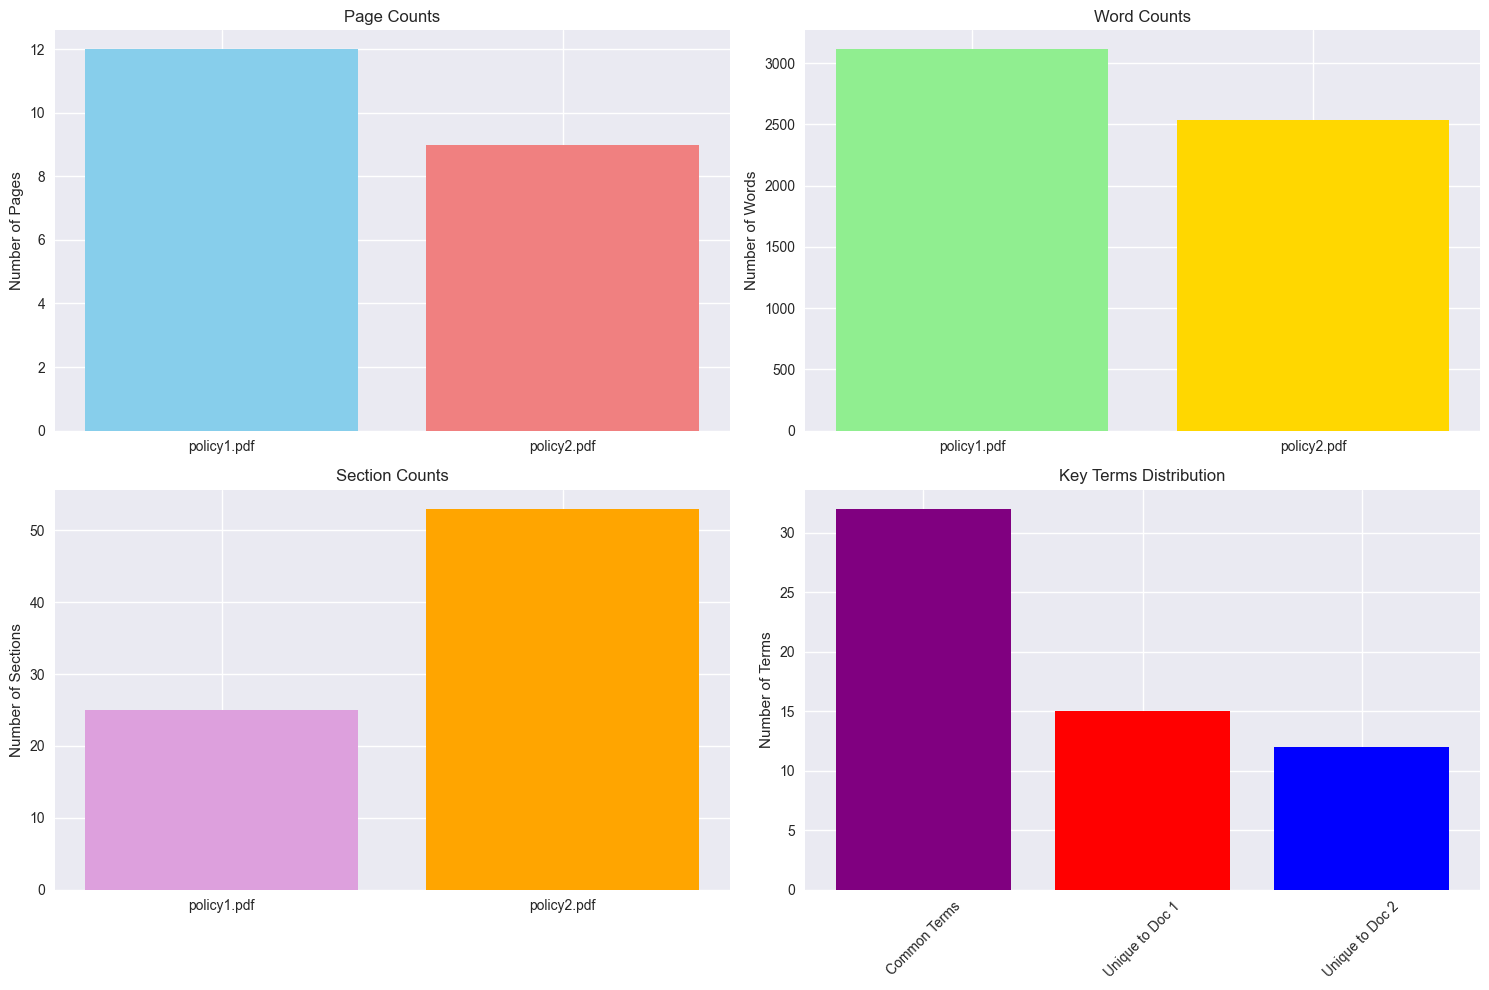


💾 Saving processed data...
✅ Data saved to processed_data/
   - rag_dataset.json: Complete dataset
   - chunks.csv: Chunks in tabular format
   - embedding_texts.json: Structured texts with policy identification
   - embedding_texts_simple.json: Simple text list (backward compatibility)
   - policy_comparison_dataset.json: Optimized for policy comparison
   - processing_summary.json: Summary and metadata

✅ Pipeline completed successfully!
📊 Summary:
   - Documents: 2
   - Chunks: 90
   - Words: 5,704
   - Ready for RAG: ✅

�� Next Steps for RAG:
1. Use embedding_texts.json with sentence-transformers
2. Implement vector database (Chroma, Pinecone, etc.)
3. Create retrieval and Q&A pipeline
4. Build user interface for policy queries


In [9]:
# Complete processing pipeline

def run_complete_pipeline(pdf_files: List[str]) -> Dict[str, Any]:
    """
    Run the complete processing pipeline.
    
    Args:
        pdf_files: List of PDF file paths
        
    Returns:
        Complete RAG dataset
    """
    print("🚀 Starting complete processing pipeline...")
    
    # Step 1: Process PDFs
    processed_docs = []
    for pdf_file in pdf_files:
        if os.path.exists(pdf_file):
            print(f"\n📄 Processing {pdf_file}...")
            doc_data = processor.process_pdf(pdf_file)
            processed_docs.append(doc_data)
            print(f"✅ Completed: {doc_data['file_name']}")
            print(f"   Pages: {doc_data['total_pages']}, Words: {doc_data['statistics']['total_words']:,}")
        else:
            print(f"❌ File not found: {pdf_file}")
    
    if not processed_docs:
        print("❌ No documents processed. Please check file paths.")
        return None
    
    # Step 2: Create RAG dataset
    print(f"\n🔧 Creating RAG dataset from {len(processed_docs)} documents...")
    rag_dataset = create_rag_dataset(processed_docs)
    
    # Step 3: Analysis and comparison
    if len(processed_docs) == 2:
        print("\n�� Comparing documents...")
        comparison = compare_documents(processed_docs[0], processed_docs[1])
        print(f"Common terms: {len(comparison['common_terms'])}")
        print(f"Unique to doc 1: {len(comparison['unique_to_doc1'])}")
        print(f"Unique to doc 2: {len(comparison['unique_to_doc2'])}")
        
        # Visualize comparison
        visualize_document_comparison(comparison)
    
    # Step 4: Save data
    print("\n💾 Saving processed data...")
    save_processed_data(rag_dataset)
    
    # Step 5: Generate report
    report = create_analysis_report(rag_dataset)
    with open('processing_report.md', 'w', encoding='utf-8') as f:
        f.write(report)
    
    print("\n✅ Pipeline completed successfully!")
    print(f"📊 Summary:")
    print(f"   - Documents: {rag_dataset['metadata']['total_documents']}")
    print(f"   - Chunks: {rag_dataset['summary']['total_chunks']}")
    print(f"   - Words: {rag_dataset['summary']['total_words']:,}")
    print(f"   - Ready for RAG: ✅")
    
    return rag_dataset

# Run the complete pipeline
if processed_docs:
    rag_dataset = run_complete_pipeline(pdf_files)
    print("\n�� Next Steps for RAG:")
    print("1. Use embedding_texts.json with sentence-transformers")
    print("2. Implement vector database (Chroma, Pinecone, etc.)")
    print("3. Create retrieval and Q&A pipeline")
    print("4. Build user interface for policy queries")
else:
    print("❌ No documents processed. Please check PDF files.")

## 8. Quick Start Guide <a name="quickstart"></a>

In [10]:
# Quick start instructions
print("""
🚀 QUICK START GUIDE
==================

1. 📁 PREPARE YOUR FILES
   - Place your insurance policy PDFs in this directory
   - Name them clearly (e.g., 'policy1.pdf', 'policy2.pdf')

2. 🔧 UPDATE FILE PATHS
   - Modify the pdf_files list in cell 2 with your actual file names
   - Or use full paths: ['/path/to/policy1.pdf', '/path/to/policy2.pdf']

3. ▶️ RUN THE PIPELINE
   - Execute the complete pipeline function
   - rag_dataset = run_complete_pipeline(pdf_files)

4. 📊 CHECK RESULTS
   - View generated visualizations
   - Check processed_data/ directory for output files
   - Read processing_report.md for summary

5. 🔍 EXPLORE THE DATA
   - rag_dataset.json: Complete structured data
   - chunks.csv: Chunks in tabular format
   - embedding_texts.json: Ready for embedding generation

6. 🎯 NEXT STEPS FOR RAG
   - Use embedding_texts.json with sentence-transformers
   - Implement vector database (Chroma, Pinecone, etc.)
   - Create retrieval and Q&A pipeline

📝 EXAMPLE USAGE:
================
# Update these paths to your actual PDF files
pdf_files = ['policy1.pdf', 'policy2.pdf']

# Run the complete pipeline
rag_dataset = run_complete_pipeline(pdf_files)

# The data is now ready for RAG implementation!
""")


🚀 QUICK START GUIDE

1. 📁 PREPARE YOUR FILES
   - Place your insurance policy PDFs in this directory
   - Name them clearly (e.g., 'policy1.pdf', 'policy2.pdf')

2. 🔧 UPDATE FILE PATHS
   - Modify the pdf_files list in cell 2 with your actual file names
   - Or use full paths: ['/path/to/policy1.pdf', '/path/to/policy2.pdf']

3. ▶️ RUN THE PIPELINE
   - Execute the complete pipeline function
   - rag_dataset = run_complete_pipeline(pdf_files)

4. 📊 CHECK RESULTS
   - View generated visualizations
   - Check processed_data/ directory for output files
   - Read processing_report.md for summary

5. 🔍 EXPLORE THE DATA
   - rag_dataset.json: Complete structured data
   - chunks.csv: Chunks in tabular format
   - embedding_texts.json: Ready for embedding generation

6. 🎯 NEXT STEPS FOR RAG
   - Use embedding_texts.json with sentence-transformers
   - Implement vector database (Chroma, Pinecone, etc.)
   - Create retrieval and Q&A pipeline

📝 EXAMPLE USAGE:
# Update these paths to your actua

In [11]:
## 9. Policy Comparison Demo <a name="comparison_demo"></a>


In [12]:
# Demo: Policy Comparison Functionality

def demo_policy_comparison():
    """
    Demonstrate how to use the policy comparison functionality.
    """
    if 'rag_dataset' not in globals():
        print("❌ Please run the complete pipeline first to generate rag_dataset")
        return
    
    print("🔍 Policy Comparison Demo")
    print("=" * 50)
    
    # Create comparison dataset
    comparison_dataset = create_policy_comparison_dataset(rag_dataset)
    
    print(f"📊 Comparison Dataset Created:")
    print(f"   - Total Policies: {comparison_dataset['metadata']['total_policies']}")
    print(f"   - Policy Names: {comparison_dataset['comparison_metadata']['policy_names']}")
    
    # Show chunks per policy
    for policy_key, policy_data in comparison_dataset['policies'].items():
        print(f"   - {policy_data['policy_name']}: {len(policy_data['chunks'])} chunks")
    
    print("\n🔍 Testing Search Across Policies:")
    
    # Test queries
    test_queries = [
        "deductible",
        "emergency room",
        "prescription drugs",
        "primary care"
    ]
    
    for query in test_queries:
        print(f"\n📝 Query: '{query}'")
        results = search_across_policies(comparison_dataset, query, top_k=3)
        
        for policy_key, policy_results in results.items():
            policy_name = comparison_dataset['policies'][policy_key]['policy_name']
            print(f"   📄 {policy_name}: {len(policy_results)} results")
            
            for i, result in enumerate(policy_results[:2], 1):  # Show top 2 results
                text_preview = result['text'][:100] + "..." if len(result['text']) > 100 else result['text']
                print(f"      {i}. {text_preview}")
    
    print("\n✅ Policy comparison functionality is working!")
    print("💡 In a real implementation, you would:")
    print("   1. Generate embeddings for each policy separately")
    print("   2. Use vector similarity search for better results")
    print("   3. Implement ranking and filtering")
    print("   4. Create a user interface for comparison")

# Run the demo
demo_policy_comparison()


🔍 Policy Comparison Demo
📊 Comparison Dataset Created:
   - Total Policies: 2
   - Policy Names: ['policy1.pdf', 'policy2.pdf']
   - policy1.pdf: 52 chunks
   - policy2.pdf: 38 chunks

🔍 Testing Search Across Policies:

📝 Query: 'deductible'
   📄 policy1.pdf: 3 results
      1. If you, the Physician, or Health Care Provider, select a Brand Drug when a Generic Drug equivalent o...
      2. If this Plan has any Calendar Year Deductible(s), Covered Services subject to that Deductible are id...
   📄 policy2.pdf: 3 results
      1. Peg is Having a Baby (9 months of in-network pre-natal care and a hospital delivery) Managing Joes T...
      2. For more information about limitations and exceptions, see the plan or policy document at www.bcbstx...

📝 Query: 'emergency room'
   📄 policy1.pdf: 2 results
      1. $0 Tubal ligation $0 Vasectomy $0 Medical nutrition therapy, not related to diabetes $0 Pregnancy an...
      2. Instead, you pay the Participating Provider payment under Inpatient facil

In [13]:
# Re-run the complete pipeline with updated structure
print("🔄 Re-running pipeline with policy comparison support...")

# Re-process the PDFs
processed_docs = []
for pdf_file in pdf_files:
    if os.path.exists(pdf_file):
        print(f"\n📄 Processing {pdf_file}...")
        doc_data = processor.process_pdf(pdf_file)
        processed_docs.append(doc_data)
        print(f"✅ Completed: {doc_data['file_name']}")

# Create RAG dataset
rag_dataset = create_rag_dataset(processed_docs)

# Save with new structure
save_processed_data(rag_dataset)

print("\n✅ Updated pipeline completed!")
print("📊 New files created:")
print("   - embedding_texts.json: Now includes policy identification")
print("   - policy_comparison_dataset.json: Optimized for comparison")
print("   - embedding_texts_simple.json: Backward compatibility")


🔄 Re-running pipeline with policy comparison support...

📄 Processing policy1.pdf...
📄 Processing PDF: policy1.pdf
✅ Successfully extracted text using PyMuPDF (12 pages)
✅ Completed: policy1.pdf

📄 Processing policy2.pdf...
📄 Processing PDF: policy2.pdf
✅ Successfully extracted text using PyMuPDF (9 pages)
✅ Completed: policy2.pdf
✅ Data saved to processed_data/
   - rag_dataset.json: Complete dataset
   - chunks.csv: Chunks in tabular format
   - embedding_texts.json: Structured texts with policy identification
   - embedding_texts_simple.json: Simple text list (backward compatibility)
   - policy_comparison_dataset.json: Optimized for policy comparison
   - processing_summary.json: Summary and metadata

✅ Updated pipeline completed!
📊 New files created:
   - embedding_texts.json: Now includes policy identification
   - policy_comparison_dataset.json: Optimized for comparison
   - embedding_texts_simple.json: Backward compatibility
